# Reproducing the study step by step

**Storage in Long-Term Energy Planning Models with Temporal Aggregation: Best Practices and Algorithms**
Bruno Borba, Md Eliasinul Islam, Taco Niet — *Environmental Research Communications* (manuscript ERC-105849)

This notebook regenerates every quantitative result of the paper from the inputs in this repository. Each model run calls `workflow/main.py` unchanged, so the notebook exercises the same code path that produced the published numbers.

| Step | Paper section | What it does | Default | Approx. cost* |
|---|---|---|---|---|
| 1 | 3.4 | Environment check against the stated versions | on | seconds |
| 2 | 3.3, Table 3 | Model inputs and time series (Figures 4–5) | on | seconds |
| 3 | 3.2 | Representative-day clustering; determinism and multi-seed robustness | on | ~30 s |
| 4 | 4.1 | Independent hand-calculated SoC verification | on | ~10 s |
| 5 | — | Reproduction check: k4h1 for WND, SOL, HYD against the archived results | on | ~1 min |
| 6 | 4.1 | Full-year hourly benchmarks k365h1 (Figure 6, Table S1) | off | ~15 min per resource, **~12 GB RAM** (Novo) |
| 7 | 4.2–4.3 | 108 aggregated configurations × 3 resources (Figures 7–8, Tables S2–S4) | off | 2–4 h (0.8 h solver time), ≤ 3 GB RAM |
| 8 | 4.2 | Table 4 and cost-error curves | on (archive or fresh) | seconds |
| 9 | 4.4 | Binding-capacity stress test, 0.2 kW·yr (Figures 9–10) | off (archive stats on) | ~20 min per resource |
| 10 | 4.3 | SoC fidelity metrics: MAE, RMSE, Pearson, rainflow (Figure 8) | on (archive) | seconds |
| 11 | 3.2 | Seed sensitivity of system cost | off | ~10 min |

\*Measured with GLPK 5.0 on an Intel Core i7 / 16 GB machine (archived run logs).

**Name mapping.** The formulation called *Novo* in the paper is implemented in `Model_Cluster`; *Niet*, *Welsch* and *Kotzur* map to `Model_Niet`, `Model_Welsch` and `Model_Kotzur`.

**Scenario labels.** `k20h1HYD` = 20 representative days, 1-hour intra-day blocks, hydro-dominated system. The suffix `_limited` marks the stress test.

## 0. Setup
Set the switches below to run the heavy steps. Everything else reads either fresh results (folder `results/`) or the archived results that accompany the paper.

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd() if (Path.cwd() / 'workflow').is_dir() else Path.cwd().parent   # repository root or notebooks/
assert (REPO / 'workflow' / 'main.py').exists(), 'Start Jupyter from the repository root or from notebooks/.'
sys.path.insert(0, str(REPO))
import src.reproduce as rp

# ---- switches for the heavy steps -------------------------------------------------------
RUN_REPRODUCTION_CHECK = True    # step 5: k4h1 x 3 resources (~1 min)
RUN_BENCHMARK          = False   # step 6: k365h1 x 3 resources (needs ~12 GB RAM for Novo)
RUN_SWEEP              = False   # step 7: full grid (2-4 h); see SWEEP_* below
RUN_STRESS             = False   # step 9: k365h1 WND and SOL with a 0.2 kW.yr cap
RUN_SEED_COSTS         = False   # step 11: optimisation under alternative k-means seeds

SWEEP_RESOURCES = ['WND', 'SOL', 'HYD']
SWEEP_K         = rp.K_VALUES          # [2..10, 20..100]
SWEEP_H         = rp.H_VALUES          # [1, 2, 4, 6, 8, 12]
FRESH = REPO / 'results'               # fresh runs are written here

# ---- archived results of the published study --------------------------------------------
PUBLISHED = REPO / 'data' / 'published_results'           # tracked subset (tables + key trajectories)
FULL_ARCHIVE = REPO / 'data' / 'full_archive'             # optional: full archive (Zenodo), all CSVs
ARCH_MAIN = FULL_ARCHIVE / 'Results_Demand_Variation' if FULL_ARCHIVE.exists() else PUBLISHED / 'main'
ARCH_LIM  = FULL_ARCHIVE / 'Results_Limited' if FULL_ARCHIVE.exists() else PUBLISHED / 'limited'
archive = rp.load_results(ARCH_MAIN / 'Simulation_Results.xlsx')
archive_lim = rp.load_results(ARCH_LIM / 'Simulation_Results.xlsx')
print(f'Archive: {len(archive)} rows, {archive.Scenario.nunique()} scenarios  ({ARCH_MAIN.relative_to(REPO)})')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
COLORS = {'Niet': '#d62728', 'Welsch': '#8c564b', 'Kotzur': '#1f77b4', 'Novo': '#2ca02c'}

Archive: 1308 rows, 327 scenarios  (data/full_archive/Results_Demand_Variation)


## 1. Computational environment (Section 3.4)
Set up with `conda env create -f env/environment-crossplatform.yml` (GLPK 5.0 from conda-forge, also on Windows). The paper reports GLPK 5.0, Python 3.13.5, otoole 1.1.5 and scikit-learn 1.7.1. Solver version affects runtimes; scikit-learn version affects clustering (before 1.4, `KMeans` defaulted to `n_init=10`; the code now sets `n_init=1` explicitly).

In [2]:
env = rp.check_environment()
env

,component,manuscript,installed,status
0,python,3.13.5,3.13.5,match
1,glpsol,5.0,5.0,match
2,otoole,1.1.5,1.1.5,match
3,scikit-learn,1.7.1,1.7.1,match
4,pandas,2.2.3,2.2.3,match
5,numpy,2.3.1,2.3.1,match


## 2. Model inputs (Section 3.3, Table 3; Figures 4–5)
A single-node system: one VRE technology (label `WINDPOWER` for all three resources; only its capacity-factor profile changes), one battery and an electricity demand. The values below are read directly from `data/system/` and the otoole defaults, i.e. what the solver actually sees.

> **Note.** Annual demand (20) and the VRE variable cost (20) are not listed in Table 3 of the R2 draft, but both change total cost.

In [3]:
import yaml
def csv_val(name, **flt):
    d = pd.read_csv(REPO / 'data' / 'system' / f'{name}.csv')
    for k, v in flt.items(): d = d[d[k] == v]
    return d['VALUE'].iloc[0] if len(d) else None
otc = yaml.safe_load(open(REPO / 'models' / 'Model_Niet' / 'otoole_config_Niet.yaml'))
cfg = yaml.safe_load(open(REPO / 'config' / 'config.yaml'))
default = lambda p: otc[p]['default']
table3 = pd.DataFrame([
    ('VRE capital cost', csv_val('CapitalCost', TECHNOLOGY='WINDPOWER'), 'data/system/CapitalCost.csv'),
    ('VRE variable cost', csv_val('VariableCost', TECHNOLOGY='WINDPOWER'), 'data/system/VariableCost.csv'),
    ('Storage capital cost (per kW.yr)', default('CapitalCostStorage'), 'otoole default'),
    ('Storage charge input ratio (1/round-trip eff.)', csv_val('InputActivityRatio', TECHNOLOGY='BATTERY_STORAGE'), 'data/system/InputActivityRatio.csv'),
    ('Storage variable cost', default('VariableCost'), 'otoole default (battery not listed in VariableCost.csv)'),
    ('Annual electricity demand', csv_val('SpecifiedAnnualDemand'), 'data/system/SpecifiedAnnualDemand.csv'),
    ('Residual storage capacity (kW.yr)', cfg['ResidualStorageCapacity'], 'config/config.yaml'),
    ('Minimum storage charge', default('MinStorageCharge'), 'otoole default'),
    ('Discount rate', default('DiscountRate'), 'otoole default'),
    ('Operational life (years)', default('OperationalLife'), 'otoole default'),
    ('Storage energy cap, unconstrained runs (kW.yr)', rp.UNCONSTRAINED_CAP, 'reproduce.py'),
    ('Storage energy cap, stress test (kW.yr)', rp.STRESS_CAP, 'reproduce.py'),
], columns=['Parameter', 'Value', 'Source'])
table3

,Parameter,Value,Source
0,VRE capital cost,1200.00,data/system/CapitalCost.csv
1,VRE variable cost,20.00,data/system/VariableCost.csv
2,Storage capital cost (per kW.yr),1000.00,otoole default
3,Storage charge input ratio (1/round-trip eff.),1.25,data/system/InputActivityRatio.csv
4,Storage variable cost,20.00,otoole default (battery not listed in Variable...
5,Annual electricity demand,20.00,data/system/SpecifiedAnnualDemand.csv
6,Residual storage capacity (kW.yr),0.05,config/config.yaml
7,Minimum storage charge,0.00,otoole default
8,Discount rate,0.05,otoole default
9,Operational life (years),1.00,otoole default


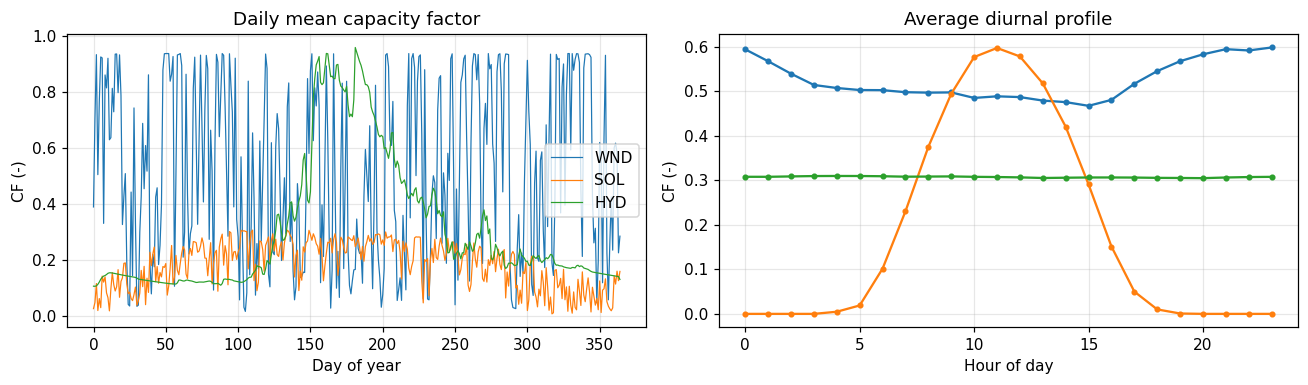

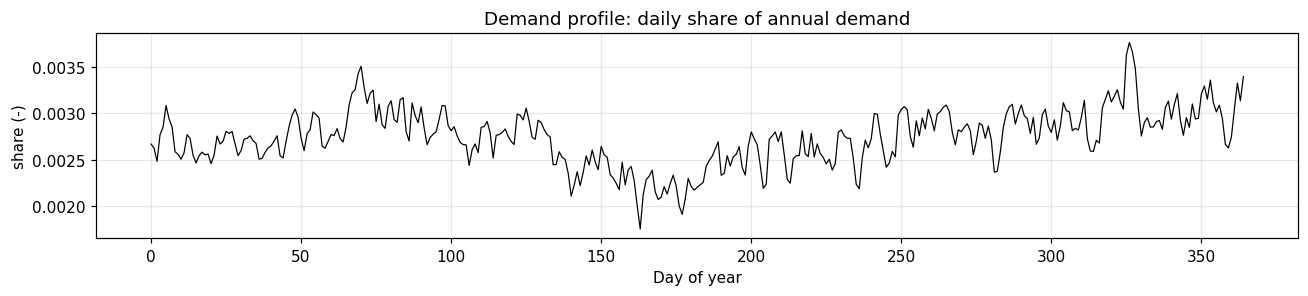

{'WND': {'mean': np.float64(0.524), 'min': np.float64(0.01), 'max': np.float64(0.939)}, 'SOL': {'mean': np.float64(0.184), 'min': np.float64(0.0), 'max': np.float64(0.941)}, 'HYD': {'mean': np.float64(0.307), 'min': np.float64(0.107), 'max': np.float64(1.0)}} | demand profile sums to 1.0


In [4]:
D = REPO / 'data' / 'timeseries'
cf = {r: pd.read_csv(D / f)['VALUE'].to_numpy() for r, f in rp.RESOURCES.items()}
dem = pd.read_csv(D / rp.DEMAND_PROFILE)['VALUE'].to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for r, v in cf.items():
    ax[0].plot(v.reshape(365, 24).mean(1), lw=.8, label=r)
    ax[1].plot(v.reshape(365, 24).mean(0), marker='o', ms=3, label=r)
ax[0].set(title='Daily mean capacity factor', xlabel='Day of year', ylabel='CF (-)')
ax[1].set(title='Average diurnal profile', xlabel='Hour of day', ylabel='CF (-)')
ax[0].legend(); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.plot(dem.reshape(365, 24).sum(1), color='k', lw=.8)
ax.set(title='Demand profile: daily share of annual demand', xlabel='Day of year', ylabel='share (-)')
plt.tight_layout(); plt.show()
print({r: dict(mean=v.mean().round(3), min=v.min().round(3), max=v.max().round(3)) for r, v in cf.items()},
      '| demand profile sums to', dem.sum().round(6))

## 3. Representative days (Section 3.2)
Each day is a 48-dimensional vector (24 min–max-scaled capacity factors and 24 scaled demand values). k-means (scikit-learn, k-means++ initialisation, `n_init = 1`, `random_state = 0`) partitions the 365 days, and the day closest to each centroid becomes the representative day. All four formulations receive the same clustering.

In [5]:
rep, seq = rp.clustering('WND', 4)
rep2, seq2 = rp.clustering('WND', 4)
print('Representative days (WND, k=4):', rep)
print('Days represented by each:', {d: seq.count(d) for d in rep})
print('Deterministic for a fixed seed:', rep == rep2 and seq == seq2)

Representative days (WND, k=4): [66, 190, 257, 296]
Days represented by each: {66: 44, 190: 84, 257: 128, 296: 109}
Deterministic for a fixed seed: True


### 3.1 Multi-seed robustness (reviewer comment C2)
The clustering is repeated with seeds 1–9 and compared with seed 0:
* **ARI**: adjusted Rand index of the day partition (1 = identical partition up to relabelling; 0 = chance level).
* **day agreement**: share of days assigned to the *same* representative day as with seed 0 (stricter, because two seeds can find the same cluster but a different medoid day).
* **same representative days**: whether the selected set of days is identical.

k,2,3,4,5,6,7,8,9,10,20,30,40,50,60,70,80,90,100
ARI,0.987,0.860,0.720,0.741,0.763,0.667,0.607,0.547,0.637,0.616,0.562,0.481,0.489,0.481,0.482,0.528,0.501,0.510
day_agreement,0.997,0.693,0.467,0.576,0.486,0.372,0.271,0.198,0.321,0.291,0.268,0.253,0.315,0.266,0.306,0.341,0.360,0.402
share identical rep-day sets,1.000,0.519,0.296,0.296,0.111,0.000,0.037,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Over all resources, k and seeds: mean ARI = 0.621 (min 0.344); mean day agreement = 0.399; identical representative-day sets in 61 of 486 comparisons.


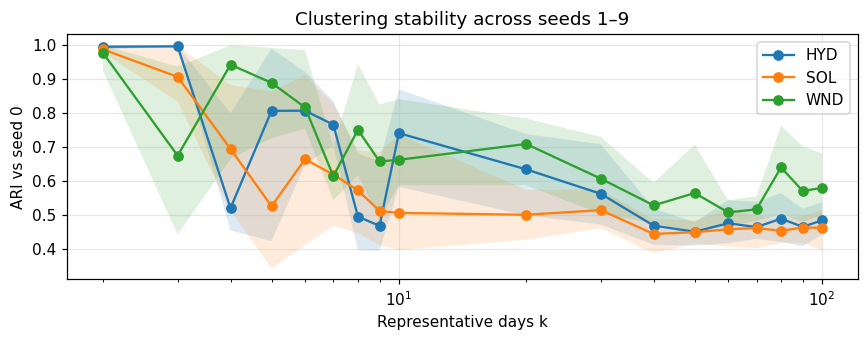

In [6]:
seeds = rp.seed_robustness()
summary_seed = (seeds.groupby('k')[['ARI', 'day_agreement', 'same_rep_days']].mean()
                     .rename(columns={'same_rep_days': 'share identical rep-day sets'}))
display(summary_seed.round(3).T)
print('Over all resources, k and seeds: mean ARI = %.3f (min %.3f); mean day agreement = %.3f; '
      'identical representative-day sets in %d of %d comparisons.'
      % (seeds.ARI.mean(), seeds.ARI.min(), seeds.day_agreement.mean(), seeds.same_rep_days.sum(), len(seeds)))
fig, ax = plt.subplots(figsize=(8, 3.2))
for r, g in seeds.groupby('resource'):
    m = g.groupby('k').ARI.agg(['mean', 'min', 'max'])
    ax.plot(m.index, m['mean'], marker='o', label=r); ax.fill_between(m.index, m['min'], m['max'], alpha=.15)
ax.set(xscale='log', xlabel='Representative days k', ylabel='ARI vs seed 0', title='Clustering stability across seeds 1–9')
ax.legend(); plt.tight_layout(); plt.show()

#### Alternative views
(a) all three metrics side by side; (b) heatmaps with exact values; (c) every seed as a dot, so the spread is visible; 
(d) ARI against day agreement: points well below the diagonal found nearly the same clusters but picked a different representative (medoid) day.

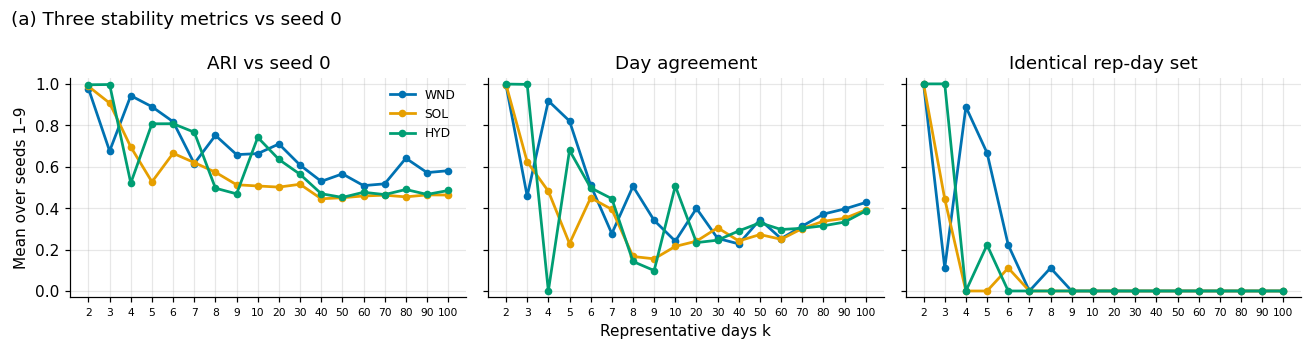

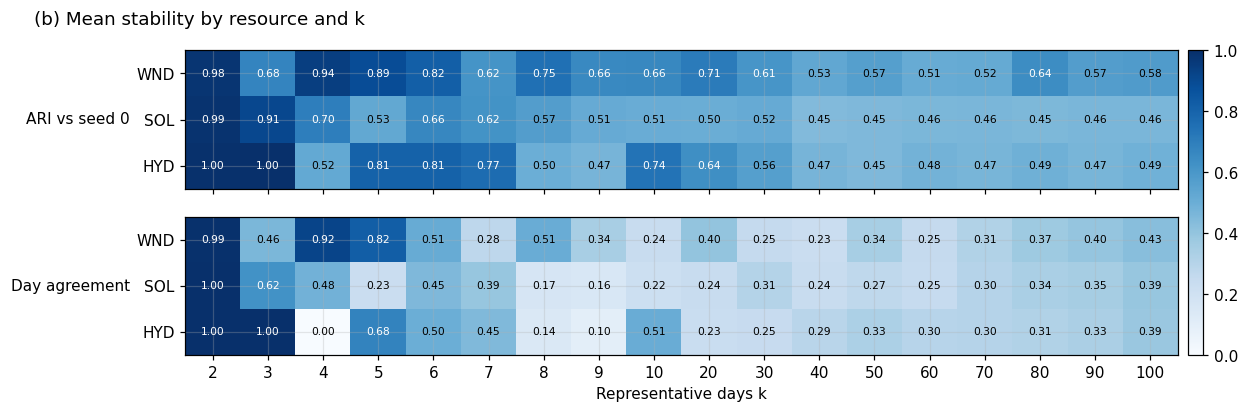

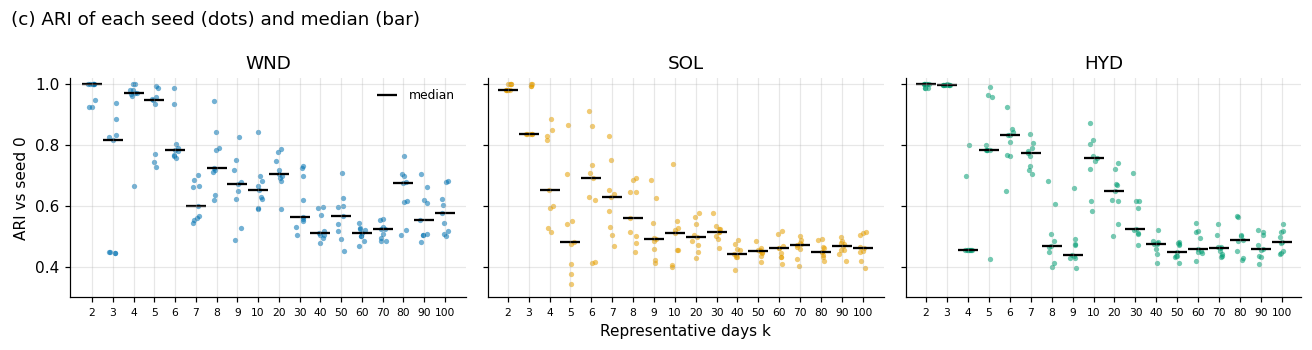

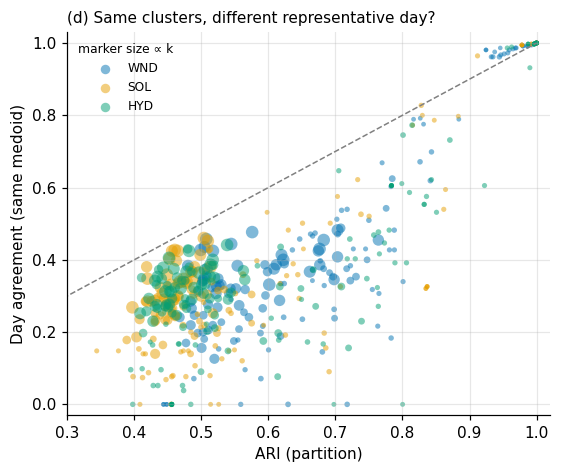

In [7]:
# Alternative views of the same `seeds` table (the plot above is kept as is)
COL = {'WND': '#0072B2', 'SOL': '#E69F00', 'HYD': '#009E73'}           # Okabe-Ito, colour-blind safe
ks = sorted(seeds.k.unique()); xi = {k: i for i, k in enumerate(ks)}    # categorical k axis (even spacing)
metrics = {'ARI': 'ARI vs seed 0', 'day_agreement': 'Day agreement', 'same_rep_days': 'Identical rep-day set'}
agg = seeds.groupby(['resource', 'k'])[list(metrics)].mean()

# (a) Small multiples: the three metrics side by side, k on an evenly spaced categorical axis
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True, sharey=True)
for ax, (col, lab) in zip(axs, metrics.items()):
    for r, c in COL.items():
        m = agg.loc[r, col]
        ax.plot([xi[k] for k in m.index], m.values, marker='o', ms=4, lw=1.8, color=c, label=r)
    ax.set(title=lab, ylim=(-0.03, 1.03), xticks=range(len(ks)))
    ax.set_xticklabels(ks, fontsize=7); ax.grid(axis='y', alpha=.3); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('Mean over seeds 1–9'); axs[1].set_xlabel('Representative days k')
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle('(a) Three stability metrics vs seed 0', x=0.01, ha='left'); plt.tight_layout(); plt.show()

# (b) Heatmaps: resource x k, mean ARI and mean day agreement, annotated
fig, axs = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True)
for ax, col in zip(axs, ['ARI', 'day_agreement']):
    h = agg[col].unstack('k').loc[list(COL)]
    im = ax.imshow(h.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(h.values):
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > .6 else 'black')
    ax.set(yticks=range(len(h)), yticklabels=h.index, xticks=range(len(ks)), xticklabels=ks)
    ax.set_ylabel(metrics[col], rotation=0, ha='right', va='center')
axs[-1].set_xlabel('Representative days k')
fig.colorbar(im, ax=axs, fraction=.02, pad=.01)
fig.suptitle('(b) Mean stability by resource and k', x=0.01, ha='left'); plt.show()

# (c) Every seed as a dot: one panel per resource, shows the spread rather than a min-max band
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
rng = np.random.default_rng(0)
for ax, (r, c) in zip(axs, COL.items()):
    g = seeds[seeds.resource == r]
    x = g.k.map(xi) + rng.uniform(-.18, .18, len(g))
    ax.scatter(x, g.ARI, s=12, color=c, alpha=.55, lw=0)
    m = g.groupby('k').ARI.median()
    ax.scatter([xi[k] for k in m.index], m.values, marker='_', s=180, color='k', lw=1.5, label='median')
    ax.set(title=r, xticks=range(len(ks)), ylim=(0.3, 1.02)); ax.set_xticklabels(ks, fontsize=7)
    ax.grid(axis='y', alpha=.3); ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('ARI vs seed 0'); axs[1].set_xlabel('Representative days k'); axs[0].legend(frameon=False, fontsize=8)
fig.suptitle('(c) ARI of each seed (dots) and median (bar)', x=0.01, ha='left'); plt.tight_layout(); plt.show()

# (d) Partition vs medoid: ARI against day agreement; points far below the diagonal found the same
#     clusters but picked a different representative day
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for r, c in COL.items():
    g = seeds[seeds.resource == r]
    ax.scatter(g.ARI, g.day_agreement, s=8 + 0.6 * g.k, color=c, alpha=.5, lw=0, label=r)
ax.plot([0, 1], [0, 1], color='grey', lw=1, ls='--')
ax.set(xlim=(0.3, 1.02), ylim=(-0.03, 1.03), xlabel='ARI (partition)', ylabel='Day agreement (same medoid)')
ax.legend(frameon=False, title='marker size ∝ k', fontsize=8, title_fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('(d) Same clusters, different representative day?', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

**Interpretation.** A fixed seed makes the comparison between formulations fair (identical inputs), but it does not make the reported error levels seed-independent. Whether the different clusterings change *cost* errors and the ranking of formulations is tested in step 11.

## 4. Independent SoC verification (Section 4.1; reviewer comment C4)
Four days A–B–A–B, four 6-h blocks per day, no losses, fixed capacities. Each occurrence of A adds 6 MWh and each B removes 6 MWh. The hand-calculated SoC sequence of each formulation (`validation/soc/independent_reference.csv`) is compared with the model output; for Kotzur and Welsch the existing intraday reconstructions are also checked.

In [8]:
soc_val = rp.run_soc_validation()
display(soc_val)
assert soc_val[['Max_native_error_MWh', 'Max_reconstructed_error_MWh']].fillna(0).abs().max().max() < 1e-6
print('All native and reconstructed SoC values match the hand calculation.')

,Formulation,Native_points,Max_native_error_MWh,Max_reconstructed_error_MWh
0,Niet,8,0.0,NaN
1,Welsch,2,0.0,0.0
2,Kotzur,4,0.0,0.0
3,Novo,16,0.0,NaN


All native and reconstructed SoC values match the hand calculation.


## 5. Reproduction check against the archived results
Runs k4h1 for the three resources (12 model solves) and compares cost, VRE capacity and storage capacity with the archived study results. Agreement to solver precision confirms that the inputs and code in this repository are those behind the paper.

In [9]:
if RUN_REPRODUCTION_CHECK:
    fresh = pd.concat([rp.run_case(r, 4, 1, results_dir=FRESH, verbose=True) for r in ['WND', 'SOL', 'HYD']])
    chk = rp.compare_to_archive(fresh, archive)
    display(chk[['Scenario', 'Model', 'Total cost (new)', 'Total cost (archive)', 'Total cost rel. diff',
                 'Storage Capacity rel. diff', 'Power Capacity rel. diff']])
    worst = chk.filter(like='rel. diff').max().max()
    print(f'Largest relative difference: {worst:.2e}')
    assert worst < 1e-6, 'Fresh results differ from the archive'

k4h1WND: done in 21.4 s
k4h1SOL: done in 23.2 s
k4h1HYD: done in 18.5 s


,Scenario,Model,Total cost (new),Total cost (archive),Total cost rel. diff,Storage Capacity rel. diff,Power Capacity rel. diff
0,k4h1WND,Model_Cluster,50762.64310,50762.64310,0.0,0.000000e+00,2.437632e-15
1,k4h1WND,Model_Kotzur,50762.64310,50762.64310,0.0,0.000000e+00,0.000000e+00
2,k4h1WND,Model_Niet,56593.84319,56593.84319,0.0,2.821359e-15,2.437634e-15
3,k4h1WND,Model_Welsch,56203.53786,56203.53786,0.0,1.223122e-14,2.193871e-14
4,k4h1SOL,Model_Cluster,152451.86590,152451.86590,0.0,6.983842e-15,0.000000e+00
5,k4h1SOL,Model_Kotzur,152431.26640,152431.26640,0.0,4.540588e-15,0.000000e+00
6,k4h1SOL,Model_Niet,156668.35310,156668.35310,0.0,2.495922e-15,0.000000e+00
7,k4h1SOL,Model_Welsch,154447.48990,154447.48990,0.0,4.427132e-14,4.077409e-14
8,k4h1HYD,Model_Cluster,82299.83452,82299.83452,0.0,2.200870e-14,4.225193e-14
9,k4h1HYD,Model_Kotzur,82299.83452,82299.83452,0.0,4.323137e-15,3.002675e-15


Largest relative difference: 4.43e-14


## 6. Full-year hourly benchmarks (Section 4.1, Figure 6, Table S1)
k = 365, h = 1 for each resource. At full resolution the mapping is the identity and all four formulations reduce to the same recursion, so their SoC curves coincide; this is a consistency check, not an independent validation. **Novo needs about 12 GB of RAM at k365h1.**

In [10]:
if RUN_BENCHMARK:
    for r in ['WND', 'SOL', 'HYD']:
        rp.run_case(r, 365, 1, results_dir=FRESH, verbose=True)

def results_source():
    # archive, with failed solves replaced by re-solved values, overridden by fresh runs
    a = archive.copy()
    failed = a['Total cost'].fillna(0) <= 0          # GLPK failure recorded as cost 0 (see Step 7)
    rerun_f = PUBLISHED / 'corrections' / 'welsch_reruns.xlsx'
    if failed.any() and rerun_f.exists():
        rr = rp.load_results(rerun_f)
        a = pd.concat([a[~failed], rr.assign(source='re-solved')], ignore_index=True)
    else:
        a = a[~failed]
    a['source'] = a.get('source', pd.Series(index=a.index, dtype=object)).fillna('archive')
    if (FRESH / 'Simulation_Results.xlsx').exists():
        f = rp.load_results(FRESH / 'Simulation_Results.xlsx')
        f = f[~f.Scenario.str.contains(r'_s\d+$')]
        key = a.Scenario + a.Model
        a = a[~key.isin(f.Scenario + f.Model)]
        a = pd.concat([a, f.assign(source='fresh')], ignore_index=True)
    return a

res = results_source()
bench = res[(res.k == 365) & (res.h == 1)]
display(bench[['resource', 'formulation', 'Total cost', 'Power Capacity', 'Storage Capacity',
               'total_time_s', 'memory_MB', 'source']].sort_values(['resource', 'formulation']))
spread = bench.groupby('resource').agg(cost_spread_pct=('Total cost', lambda x: 100 * (x.max() - x.min()) / x.min()),
                                       cap_spread=('Storage Capacity', lambda x: x.max() - x.min()))
display(spread.round(3))

,resource,formulation,Total cost,Power Capacity,Storage Capacity,total_time_s,memory_MB,source
430,HYD,Kotzur,90836.46212,70.096498,6.057958,82.98,613.4,archive
431,HYD,Niet,90840.54802,70.096498,6.062044,319.63,193.0,archive
429,HYD,Novo,90840.56147,70.096498,6.062057,491.14,10814.0,archive
432,HYD,Welsch,90852.86695,70.096498,6.074362,294.54,1051.7,archive
1,SOL,Kotzur,153297.51630,124.180955,3.386068,61.94,621.3,archive
2,SOL,Niet,153330.27880,124.180955,3.418831,115.51,185.8,archive
0,SOL,Novo,153330.28640,124.180955,3.418838,421.55,12195.1,archive
3,SOL,Welsch,153352.63050,124.180955,3.441182,242.08,1042.0,archive
859,WND,Kotzur,51014.00809,41.159057,0.955107,156.29,613.4,archive
860,WND,Niet,51015.84985,41.159057,0.956949,134.68,193.0,archive


,cost_spread_pct,cap_spread
resource,,
HYD,0.018,0.016
SOL,0.036,0.055
WND,0.077,0.040


The R2 Table 4 note states that at full resolution the formulations agree within 0.08 % on cost and 0.03 kW·yr on capacity. The spread table above is the direct check of that sentence.

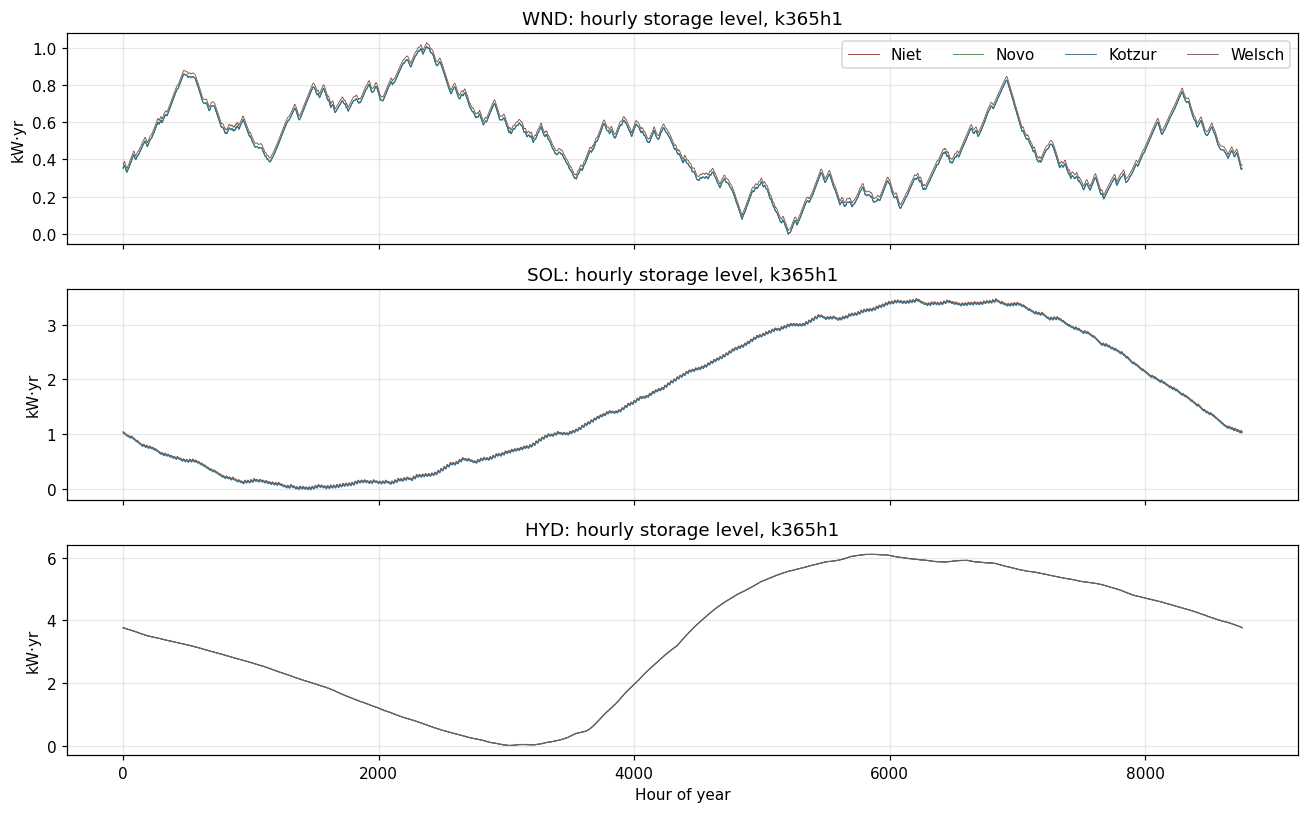

In [11]:
src_dir = FRESH if (FRESH / 'k365h1WND_Storage_Level_Model_Niet.csv').exists() else ARCH_MAIN
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, r in zip(axes, ['WND', 'SOL', 'HYD']):
    for f, m in [('Niet', 'Niet'), ('Novo', 'Cluster'), ('Kotzur', 'Kotzur_intraday'), ('Welsch', 'Welsch_intraday')]:
        p = src_dir / f'k365h1{r}_Storage_Level_Model_{m}.csv'
        if p.exists():
            ax.plot(rp.read_storage(src_dir, f'k365h1{r}', m), lw=.6, color=COLORS[f], label=f)
    ax.set(ylabel='kW·yr', title=f'{r}: hourly storage level, k365h1')
axes[0].legend(ncol=4); axes[-1].set_xlabel('Hour of year'); plt.tight_layout(); plt.show()

## 7. Aggregated configurations (Sections 4.2–4.3)
18 values of k × 6 block lengths h = 108 configurations per resource, each solved with all four formulations. Completed scenarios are skipped, so the cell can be interrupted and resumed. The runtime estimate below is taken from the archived logs.

In [12]:
grid = archive[(archive.k != 365) & archive.resource.isin(SWEEP_RESOURCES) & archive.k.isin(SWEEP_K) & archive.h.isin(SWEEP_H)]
print(f'Selected grid: {grid.Scenario.nunique()} scenarios, {len(grid)} solves; '
      f'archived wall time {grid.total_time_s.sum() / 3600:.1f} h, peak memory {grid.memory_MB.max() / 1024:.1f} GB')
if RUN_SWEEP:
    rp.run_grid(SWEEP_RESOURCES, SWEEP_K, SWEEP_H, results_dir=FRESH)

Selected grid: 324 scenarios, 1296 solves; archived wall time 0.8 h, peak memory 2.9 GB


### 7.1 Audit of the archived sweep: failed solves
Eight archived Welsch solves report a total cost of exactly 0. GLPK's primal simplex stopped with *"unable to recover undefined or non-optimal solution"*, and the original pipeline then read the result CSVs left over from the previous scenario, so the capacities in these rows are stale. `src/simulation.py` now detects non-optimal termination, retries with `--nopresol`, `--dual` and `--exact` (identical optima where tested) and never reports capacities from a failed solve. The re-solved values are in `data/published_results/corrections/welsch_reruns.xlsx` and replace the failed rows in all tables below.

In [13]:
failed = archive[archive['Total cost'].fillna(0) <= 0]
display(failed[['Scenario', 'Model', 'Total cost', 'Power Capacity', 'Storage Capacity']])
rr_f = PUBLISHED / 'corrections' / 'welsch_reruns.xlsx'
if rr_f.exists():
    rr = rp.add_errors(pd.concat([rp.load_results(rr_f), archive[(archive.k == 365) & (archive.Model == 'Model_Cluster')]]))
    display(rr[rr.k != 365][['Scenario', 'Model', 'Total cost', 'Power Capacity', 'Storage Capacity', 'cost_err_pct', 'cap_err_pct']].round(3))

,Scenario,Model,Total cost,Power Capacity,Storage Capacity
79,k5h1SOL,Model_Welsch,0.0,115.266936,6.280452
127,k7h1SOL,Model_Welsch,0.0,114.010711,4.775415
151,k8h1SOL,Model_Welsch,0.0,118.072735,5.597867
511,k4h12HYD,Model_Welsch,0.0,66.258262,2.128255
543,k6h2HYD,Model_Welsch,0.0,69.030964,2.822310
555,k6h8HYD,Model_Welsch,0.0,69.022945,2.803670
959,k5h4WND,Model_Welsch,0.0,41.392659,7.357507
1015,k7h8WND,Model_Welsch,0.0,43.353997,6.126450


,Scenario,Model,Total cost,Power Capacity,Storage Capacity,cost_err_pct,cap_err_pct
0,k4h12HYD,Model_Welsch,82162.458,66.258,2.123,-9.553,-64.986
1,k6h2HYD,Model_Welsch,86178.267,69.023,2.818,-5.132,-53.515
2,k6h8HYD,Model_Welsch,86111.206,68.989,2.794,-5.206,-53.917
4,k5h1SOL,Model_Welsch,152095.499,122.039,4.758,-0.805,39.157
5,k7h1SOL,Model_Welsch,158053.098,126.273,5.618,3.080,64.336
6,k8h1SOL,Model_Welsch,149402.534,120.532,3.878,-2.562,13.425
8,k5h4WND,Model_Welsch,57738.286,41.385,7.349,13.177,667.937
9,k7h8WND,Model_Welsch,58672.335,43.237,6.095,15.008,536.902


## 8. Table 4 and cost-error curves (Section 4.2; Figure 7)
Errors are relative to the k365h1 Novo benchmark of the same resource and are computed from **unrounded** values.

In [14]:
res = results_source()
t4 = rp.table4(res)
display(t4.style.format({'Total cost': '{:,.0f}', 'Cost error (%)': '{:+.1f}', 'Storage capacity (kW·yr)': '{:.2f}',
                         'Capacity error (%)': '{:+.1f}', 'Runtime (s)': '{:.2f}', 'Memory (MB)': '{:.1f}'}))

,Scenario,Case,Formulation,Total cost,Cost error (%),Storage capacity (kW·yr),Capacity error (%),Runtime (s),Memory (MB)
0,WND,k365h1,Niet,"51,016",-0.0,0.96,-0.0,134.68,193.0
1,WND,k365h1,Welsch,"51,054",+0.1,0.99,+3.9,256.97,1051.7
2,WND,k365h1,Kotzur,"51,014",-0.0,0.96,-0.2,156.29,613.4
3,WND,k365h1,Novo,"51,016",+0.0,0.96,+0.0,427.28,10814.0
4,WND,k8h1,Niet,"57,305",+12.3,7.45,+678.9,0.30,4.9
5,WND,k8h1,Welsch,"57,380",+12.5,7.53,+686.7,0.67,13.9
6,WND,k8h1,Kotzur,"51,419",+0.8,1.57,+63.9,0.53,6.5
7,WND,k8h1,Novo,"51,424",+0.8,1.57,+64.4,6.17,281.7
8,WND,k20h1,Niet,"53,945",+5.7,4.28,+347.0,0.73,11.2
9,WND,k20h1,Welsch,"53,942",+5.7,4.27,+346.7,1.36,35.0


**Traceability check.** The R2 draft's Table 4 values are entered below and compared with the recomputed values. Costs and capacities agree exactly. Some capacity errors differ by up to ~3 percentage points because the draft divides by the benchmark rounded to two decimals (e.g. WND k8h1 Niet: 7.45/0.96 − 1 = +676.0 % versus +678.9 % unrounded).

In [15]:
draft = pd.DataFrame([  # Table 4 of the R2 draft (cost error %, capacity error %)
 ('WND','k8h1','Niet',57305,12.3,7.45,676.0),('WND','k8h1','Welsch',57380,12.5,7.53,684.4),('WND','k8h1','Kotzur',51419,0.8,1.57,63.5),('WND','k8h1','Novo',51424,0.8,1.57,63.5),
 ('WND','k20h1','Niet',53945,5.7,4.28,345.8),('WND','k20h1','Welsch',53942,5.7,4.27,344.8),('WND','k20h1','Kotzur',50811,-0.4,1.14,18.7),('WND','k20h1','Novo',50821,-0.4,1.15,19.8),
 ('SOL','k9h1','Niet',153697,0.2,6.21,81.6),('SOL','k9h1','Welsch',152467,-0.6,4.98,45.6),('SOL','k9h1','Kotzur',150998,-1.5,3.51,2.6),('SOL','k9h1','Novo',151023,-1.5,3.53,3.2),
 ('SOL','k20h1','Niet',157988,3.0,5.44,59.1),('SOL','k20h1','Welsch',157591,2.8,5.04,47.4),('SOL','k20h1','Kotzur',156927,2.3,4.38,28.1),('SOL','k20h1','Novo',156960,2.4,4.41,28.9),
 ('HYD','k7h1','Niet',87513,-3.7,3.76,-38.0),('HYD','k7h1','Welsch',87659,-3.5,3.91,-35.5),('HYD','k7h1','Kotzur',87473,-3.7,3.72,-38.6),('HYD','k7h1','Novo',87473,-3.7,3.72,-38.6),
 ('HYD','k20h1','Niet',89921,-1.0,5.09,-16.0),('HYD','k20h1','Welsch',90016,-0.9,5.19,-14.4),('HYD','k20h1','Kotzur',89831,-1.1,5.00,-17.5),('HYD','k20h1','Novo',89832,-1.1,5.00,-17.5)],
 columns=['Scenario','Case','Formulation','cost_draft','cost_err_draft','cap_draft','cap_err_draft'])
tr = draft.merge(t4, on=['Scenario', 'Case', 'Formulation'])
tr['cost diff'] = tr['Total cost'].round(0) - tr['cost_draft']
tr['cap diff'] = tr['Storage capacity (kW·yr)'].round(2) - tr['cap_draft']
tr['cost-err diff (pp)'] = tr['Cost error (%)'].round(1) - tr['cost_err_draft']
tr['cap-err diff (pp)'] = tr['Capacity error (%)'].round(1) - tr['cap_err_draft']
display(tr[['Scenario', 'Case', 'Formulation', 'cost diff', 'cap diff', 'cost-err diff (pp)', 'cap-err diff (pp)']])

,Scenario,Case,Formulation,cost diff,cap diff,cost-err diff (pp),cap-err diff (pp)
0,WND,k8h1,Niet,0.0,0.0,0.0,2.9
1,WND,k8h1,Welsch,0.0,0.0,0.0,2.3
2,WND,k8h1,Kotzur,0.0,0.0,0.0,0.4
3,WND,k8h1,Novo,0.0,0.0,0.0,0.9
4,WND,k20h1,Niet,0.0,0.0,0.0,1.2
5,WND,k20h1,Welsch,0.0,0.0,0.0,1.9
6,WND,k20h1,Kotzur,0.0,0.0,0.0,0.8
7,WND,k20h1,Novo,0.0,0.0,0.0,0.7
8,SOL,k9h1,Niet,0.0,0.0,0.0,0.0
9,SOL,k9h1,Welsch,0.0,0.0,0.0,0.0


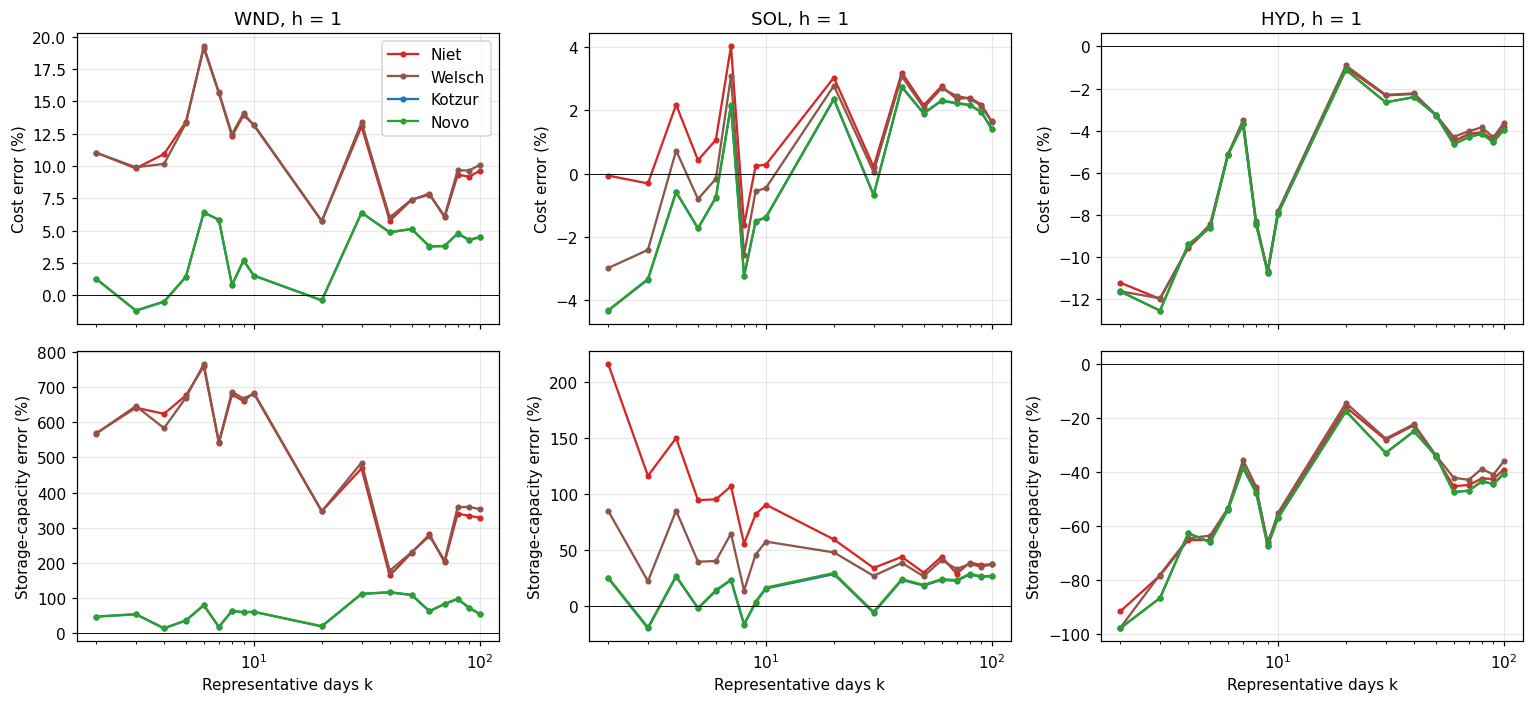

In [16]:
d = rp.add_errors(res[~res.limited])      # benchmark must be present when errors are computed
d = d[d.k != 365]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for j, r in enumerate(['WND', 'SOL', 'HYD']):
    for f in ['Niet', 'Welsch', 'Kotzur', 'Novo']:
        g = d[(d.resource == r) & (d.formulation == f) & (d.h == 1)].sort_values('k')
        axes[0, j].plot(g.k, g.cost_err_pct, marker='o', ms=3, color=COLORS[f], label=f)
        axes[1, j].plot(g.k, g.cap_err_pct, marker='o', ms=3, color=COLORS[f], label=f)
    axes[0, j].set(title=f'{r}, h = 1', ylabel='Cost error (%)'); axes[1, j].set(xlabel='Representative days k', ylabel='Storage-capacity error (%)', xscale='log')
    for a in axes[:, j]: a.axhline(0, color='k', lw=.6)
axes[0, 0].legend(); plt.tight_layout(); plt.show()

# intra-day resolution: cost error vs h (median over k)
piv = d.groupby(['resource', 'formulation', 'h']).cost_err_pct.apply(lambda x: x.abs().median()).unstack('h')
display(piv.round(2).style.set_caption('Median |cost error| (%) across k, by block length h'))

In [17]:
# Computational burden (all aggregated configurations)
cb = res[~res.limited].groupby(['resource', 'formulation'])[['total_time_s', 'memory_MB']].median().unstack('formulation')
display(cb.round(2).style.set_caption('Median matrix-generation + solve time (s) and memory (MB)'))

## 9. Binding storage-capacity stress test (Section 4.4; Figures 9–10)
Full-year hourly runs with total storage energy capacity capped at 0.2 kW·yr (`StorageMaxCapacity = 0.2`; reported *new* capacity is then 0.15 because 0.05 is residual). Kotzur verifies SoC only at day boundaries, so its reconstructed hourly trajectory can leave the bounds.

Two counting conventions are reported. *Strict* counts physically infeasible states (SoC > 0.2 or < 0). *At or beyond* also counts hours exactly at the upper bound, which are feasible; the R2 draft's wind figure (224 h; 183 above) corresponds to this second convention.

In [18]:
if RUN_STRESS:
    for r in ['WND', 'SOL']:
        rp.run_case(r, 365, 1, cap=rp.STRESS_CAP, results_dir=FRESH, verbose=True)

STRESS_SOURCES = {'fresh': FRESH, 'regenerated R2 (paper inputs)': PUBLISHED / 'stress_R2', 'archive': ARCH_LIM}
rows = []
for r in ['WND', 'SOL']:
    name = f'k365h1{r}_limited'
    for label, d_ in STRESS_SOURCES.items():
        if not (d_ / f'{name}_Storage_Level_Model_Kotzur_intraday.csv').exists():
            continue
        tab = rp.load_results(d_ / 'Simulation_Results.xlsx')   # cap is not encoded in file names
        t = tab[tab.Scenario == name].set_index('formulation')
        cap = t.loc['Kotzur', 'Storage Capacity'] + rp.RESIDUAL_STORAGE
        for f, m in [('Kotzur', 'Kotzur_intraday'), ('Niet', 'Niet'), ('Novo', 'Cluster'), ('Welsch', 'Welsch_intraday')]:
            if (d_ / f'{name}_Storage_Level_Model_{m}.csv').exists():
                v = rp.soc_violations(rp.read_storage(d_, name, m), upper=cap)
                rows.append({'resource': r, 'source': label, 'formulation': f, 'cap (kW.yr)': round(cap, 4),
                             'total cost': t.loc[f, 'Total cost'] if f in t.index else np.nan, **v})
stress = pd.DataFrame(rows)
display(stress.round(4))

,resource,source,formulation,cap (kW.yr),total cost,n,max,min,above_strict,below_strict,total_strict,share_strict_pct,at_or_above_upper,total_if_counting_at_bound,share_if_counting_at_bound_pct
0,WND,regenerated R2 (paper inputs),Kotzur,0.2,136990.7749,8760,0.2274,-0.0295,67,40,107,1.2215,187,227,2.5913
1,WND,regenerated R2 (paper inputs),Niet,0.2,227531.9429,8760,0.2000,0.0000,0,0,0,0.0000,197,197,2.2489
2,WND,regenerated R2 (paper inputs),Welsch,0.2,227533.1312,8760,0.2000,0.0000,0,0,0,0.0000,1,1,0.0114
3,WND,archive,Kotzur,0.2,126111.2565,8760,0.2213,-0.0271,114,41,155,1.7694,183,224,2.5571
4,WND,archive,Niet,0.2,136451.2731,8760,0.2000,0.0000,0,0,0,0.0000,13,13,0.1484
5,WND,archive,Novo,0.2,136451.4557,8760,0.2000,0.0000,0,0,0,0.0000,60,60,0.6849
6,WND,archive,Welsch,0.2,143270.6770,8760,0.1956,-0.0000,0,0,0,0.0000,0,0,0.0000
7,SOL,regenerated R2 (paper inputs),Kotzur,0.2,413582.2431,8760,0.2258,-0.0175,267,215,482,5.5023,277,492,5.6164
8,SOL,regenerated R2 (paper inputs),Niet,0.2,426705.3476,8760,0.2000,0.0000,0,0,0,0.0000,45,45,0.5137
9,SOL,regenerated R2 (paper inputs),Welsch,0.2,457891.1365,8760,0.1954,0.0000,0,0,0,0.0000,0,0,0.0000


**Provenance of the Section 4.4 numbers.**
* *Solar*: the regenerated run with the paper's inputs reproduces the R2 text exactly (max 0.2258, min −0.0175, 267 h above, 215 h below, 482 h = 5.50 %, strict counting). The archived solar "limited" run used a cap of 3.0 kW·yr and is unrelated.
* *Wind*: the R2 values (max 0.2213, min −0.0271) come from the archived run, whose costs differ from a run with the paper's inputs. That run therefore used different inputs from the main study. The regenerated wind run should replace it (Figure 9 and the text). Its hours-above-bound must be counted strictly, like solar: the R2 figure of 183 h counts hours exactly at the bound.
* The regenerated runs omit Novo, which needs ~12 GB of RAM at k365h1; Novo does not affect the Kotzur trajectory. Set `RUN_STRESS = True` on a 16 GB machine to complete them.
* Cost column: under the binding cap, Kotzur's total cost is clearly lower than that of the formulations that keep SoC within bounds. The claim that the violations do not materially alter cost should be revisited.

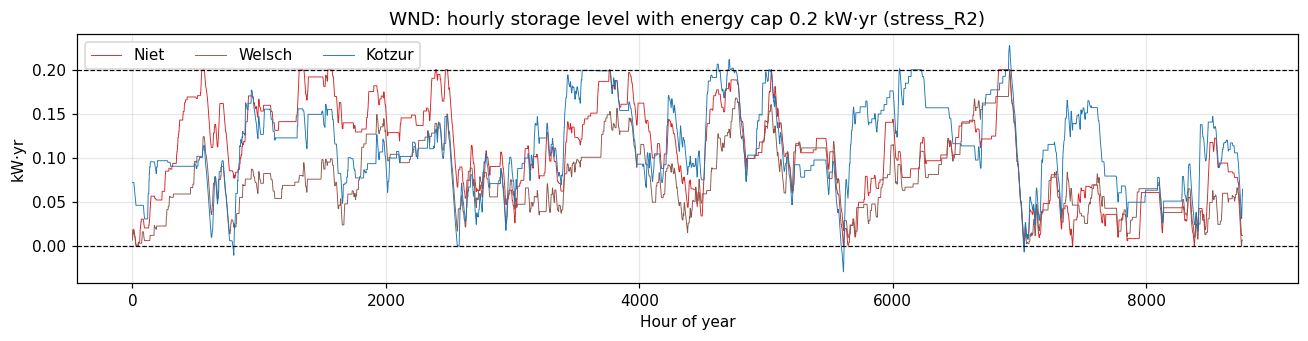

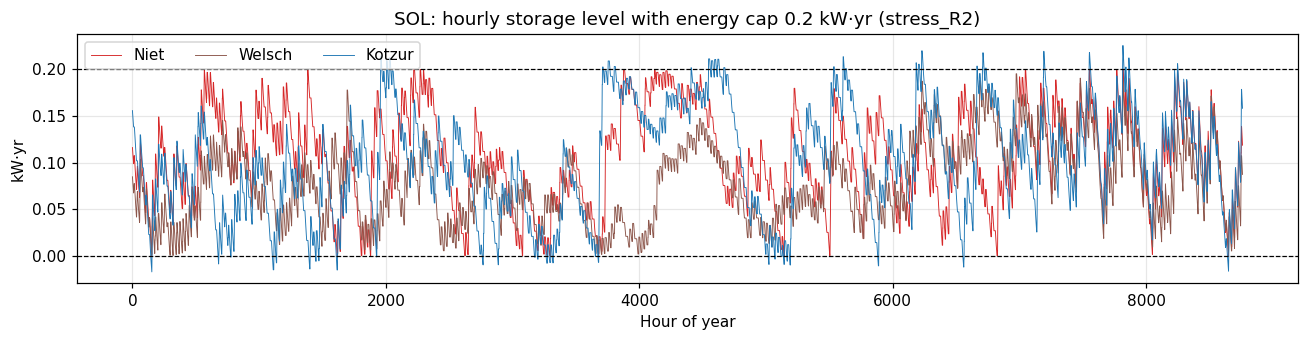

In [19]:
for r in ['WND', 'SOL']:
    name = f'k365h1{r}_limited'
    d_ = next((d for d in STRESS_SOURCES.values() if (d / f'{name}_Storage_Level_Model_Kotzur_intraday.csv').exists()), None)
    if d_ is None:
        continue
    cap = stress[(stress.resource == r) & (stress.source == [k for k, v in STRESS_SOURCES.items() if v == d_][0])]['cap (kW.yr)'].iloc[0]
    fig, ax = plt.subplots(figsize=(12, 3.2))
    for f, m in [('Niet', 'Niet'), ('Novo', 'Cluster'), ('Welsch', 'Welsch_intraday'), ('Kotzur', 'Kotzur_intraday')]:
        p = d_ / f'{name}_Storage_Level_Model_{m}.csv'
        if p.exists():
            ax.plot(rp.read_storage(d_, name, m), lw=.6, color=COLORS[f], label=f)
    ax.axhline(cap, color='k', ls='--', lw=.8); ax.axhline(0, color='k', ls='--', lw=.8)
    ax.set(title=f'{r}: hourly storage level with energy cap {cap} kW·yr ({d_.name})', xlabel='Hour of year', ylabel='kW·yr')
    ax.legend(ncol=4); plt.tight_layout(); plt.show()

## 10. SoC fidelity metrics (Section 4.3; Figure 8)
The repository did not contain the script used for Figure 8, so the metrics are **re-implemented** here with explicit definitions:
* each aggregated trajectory is expanded to 8760 h (Novo and Kotzur: chronological blocks, Kotzur reconstructed; Welsch: its reconstructed trajectory in native grouped day-type order, as in `graph_generator.py`; Niet: representative blocks held for their year-split duration);
* MAE, RMSE and Pearson r against the k365h1 benchmark;
* rainflow counting (ASTM E1049, half cycles = 0.5) of each trajectory, compared with the benchmark count.

Values may differ from the published Figure 8 if the original script used other alignment conventions; the definitions above should be stated in the paper.

In [20]:
CASES = [('WND', 8, 1), ('WND', 20, 1), ('SOL', 9, 1), ('SOL', 20, 1), ('HYD', 7, 1), ('HYD', 20, 1)]
rows = []
for r, k, h in CASES:
    name = f'k{k}h{h}{r}'
    d_ = FRESH if (FRESH / f'{name}_Storage_Level_Model_Cluster.csv').exists() else ARCH_MAIN
    bdir = FRESH if (FRESH / f'k365h1{r}_Storage_Level_Model_Niet.csv').exists() else ARCH_MAIN
    if not (d_ / f'{name}_Storage_Level_Model_Cluster.csv').exists():
        print(f'{name}: trajectories not available (download the full archive)'); continue
    b = rp.read_storage(bdir, f'k365h1{r}', 'Niet').to_numpy()
    for f in ['Niet', 'Welsch', 'Kotzur', 'Novo']:
        try:
            t = rp.hourly_trajectory(d_, name, f, h)
            rows.append({'case': name, 'formulation': f, **rp.fidelity_metrics(b, t)})
        except FileNotFoundError as e:
            print(e)
fid = pd.DataFrame(rows)
if fid.empty:
    print('No trajectories found: place the full archive in data/full_archive/ or run the cases.')
else:
    fid['cycle error (%)'] = 100 * (fid.rainflow_cycles / fid.rainflow_cycles_benchmark - 1)
    display(fid.round(4))

,case,formulation,MAE,RMSE,Pearson,rainflow_cycles,rainflow_cycles_benchmark,cycle error (%)
0,k8h1WND,Niet,3.8406,4.5450,-0.7621,6.0,241.5,-97.5155
1,k8h1WND,Welsch,3.9106,4.6406,-0.7562,199.0,241.5,-17.5983
2,k8h1WND,Kotzur,0.3393,0.3993,0.9178,187.5,241.5,-22.3602
3,k8h1WND,Novo,0.3432,0.4030,0.9178,187.5,241.5,-22.3602
4,k20h1WND,Niet,1.5785,1.8523,-0.2928,16.0,241.5,-93.3747
5,k20h1WND,Welsch,1.5190,1.7895,-0.2894,210.0,241.5,-13.0435
6,k20h1WND,Kotzur,0.1517,0.1914,0.8344,189.0,241.5,-21.7391
7,k20h1WND,Novo,0.1535,0.1938,0.8344,189.0,241.5,-21.7391
8,k9h1SOL,Niet,1.2404,1.4084,0.8868,8.5,354.5,-97.6023
9,k9h1SOL,Welsch,0.6273,0.7672,0.9487,323.5,354.5,-8.7447


## 11. Seed sensitivity of system cost (reviewer comment C2)
Re-solves selected configurations with seeds 1 and 2 and compares total-cost error with seed 0. The question is whether the seed-induced spread is small compared with the differences between formulations.

In [21]:
SEED_DIR = REPO / 'results' / 'seeds'
if RUN_SEED_COSTS:
    for s in [1, 2]:
        for r in ['WND', 'SOL', 'HYD']:
            for k in [4, 8, 20]:
                rp.run_case(r, k, 1, random_state=s, results_dir=SEED_DIR, suffix=f'_s{s}', verbose=True)
sd = None
if (SEED_DIR / 'Simulation_Results.xlsx').exists():
    sd = rp.load_results(SEED_DIR / 'Simulation_Results.xlsx')
elif (PUBLISHED / 'seeds' / 'seed_runs.xlsx').exists():
    sd = rp.load_results(PUBLISHED / 'seeds' / 'seed_runs.xlsx')
if sd is not None:
    sd['seed'] = sd.Scenario.str.extract(r'_s(\d+)$')[0].astype(int)
    sd['resource'] = sd.Scenario.str.extract(r'(WND|SOL|HYD)')[0]
    _r = results_source()
    base = _r[(_r.h == 1) & _r.k.isin(sd.k.unique()) & ~_r.limited].assign(seed=0)
    allseeds = pd.concat([base, sd], ignore_index=True)
    bm = archive[(archive.k == 365) & (archive.Model == 'Model_Cluster')].set_index('resource')['Total cost']
    allseeds['cost_err_pct'] = 100 * (allseeds['Total cost'] / allseeds.resource.map(bm) - 1)
    piv = allseeds.pivot_table(index=['resource', 'k', 'formulation'], columns='seed', values='cost_err_pct')
    piv['seed spread (pp)'] = piv.max(1) - piv.min(1)
    display(piv.round(2))
    between = allseeds[allseeds.seed == 0].groupby(['resource', 'k']).cost_err_pct.agg(lambda x: x.max() - x.min())
    within = piv['seed spread (pp)'].groupby(level=[0, 1]).max()
    cmp_ = pd.DataFrame({'max seed spread (pp)': within, 'between-formulation range, seed 0 (pp)': between})
    display(cmp_.round(2))
    best = (allseeds.assign(a=allseeds.cost_err_pct.abs()).sort_values('a')
                    .groupby(['resource', 'k', 'seed']).formulation.first().unstack('seed'))
    display(best.rename_axis(columns='seed').style.set_caption('Formulation with the smallest |cost error|'))
    cap_piv = allseeds.pivot_table(index=['resource', 'k', 'formulation'], columns='seed',
                                   values='Storage Capacity')
    display(cap_piv.round(3).style.set_caption('Storage capacity (kW·yr) by seed'))

seed                         0      1      2  seed spread (pp)
resource k  formulation                                       
HYD      4  Kotzur       -9.40  -4.06  -5.69              5.34
            Niet         -9.57  -3.97  -5.21              5.60
            Novo         -9.40  -4.06  -5.69              5.34
            Welsch       -9.53  -3.90  -5.29              5.63
         8  Kotzur       -8.46  -7.16  -3.31              5.15
            Niet         -8.39  -7.01  -3.01              5.37
            Novo         -8.46  -7.16  -3.31              5.15
            Welsch       -8.31  -6.95  -3.03              5.28
         20 Kotzur       -1.11  -4.91  -5.94              4.82
            Niet         -1.01  -4.82  -5.99              4.97
            Novo         -1.11  -4.91  -5.94              4.82
            Welsch       -0.91  -4.80  -5.90              4.99
SOL      4  Kotzur       -0.59  -0.40  -1.58              1.17
            Niet          2.18   2.40   1.29              1.11
            Novo         -0.57  -0.39  -1.56              1.17
            Welsch        0.73   0.98  -0.32              1.30
         8  Kotzur       -3.25  -0.05  -4.35              4.29
            Niet         -1.63   1.72  -2.48              4.20
            Novo         -3.23  -0.04  -4.32              4.29
            Welsch       -2.56   0.77  -3.28              4.04
         20 Kotzur        2.35   3.70  -0.30              4.00
            Niet          3.04   4.67   0.84              3.83
            Novo          2.37   3.71  -0.29              4.00
            Welsch        2.78   4.39   0.58              3.81
WND      4  Kotzur       -0.50   0.33  -0.77              1.10
            Niet         10.93  11.67  10.81              0.86
            Novo         -0.50   0.33  -0.77              1.10
            Welsch       10.17  11.09  10.09              1.00
         8  Kotzur        0.79   2.97   4.39              3.60
            Niet         12.33  10.86  14.20              3.34
            Novo          0.80   2.99   4.41              3.61
            Welsch       12.47  10.91  14.35              3.44
         20 Kotzur       -0.40   4.33   5.29              5.69
            Niet          5.74   9.38  13.75              8.01
            Novo         -0.38   4.34   5.30              5.69
            Welsch        5.74   9.34  13.79              8.05

max seed spread (pp)  between-formulation range, seed 0 (pp)
resource k                                                               
HYD      4                   5.63                                    0.17
         8                   5.37                                    0.15
         20                  4.99                                    0.20
SOL      4                   1.30                                    2.76
         8                   4.29                                    1.62
         20                  4.00                                    0.69
WND      4                   1.10                                   11.43
         8                   3.61                                   11.68
         20                  8.05                                    6.14

**Reading the result.** Seed-induced spreads in cost error reach several percentage points (largest for HYD and WND at k = 20). For HYD the spread exceeds the between-formulation differences, while for WND at small k the gap between {Kotzur, Novo} and {Niet, Welsch} remains larger than the seed spread (WND k ≤ 8: separation 7.9–11.5 pp vs spread ≤ 3.6 pp). The qualitative grouping of formulations is therefore robust, but individual error levels in Table 4 are clustering-dependent and should be reported as such.

## 12. Where each published number comes from
| Claim in the paper | Reproduced in |
|---|---|
| Section 3.2 clustering settings | Step 3 |
| Section 4.1 hand-calculated SoC check | Step 4 (`validation/soc/`) |
| Figure 6, Table S1 | Step 6 |
| Table 4, Figure 7, Tables S2–S4 | Steps 7–8 |
| Section 4.4 wind/solar violation statistics, Figures 9–10 | Step 9 |
| Figure 8 metrics | Step 10 (re-implementation) |
| C2 multi-seed robustness | Steps 3.1 and 11 |

Fresh runs go to `results/`; the archive is in `data/published_results/` (tables and key trajectories) and, in full, in the Zenodo record cited in the Data Availability Statement.